Universidad Torcuato Di Tella

*Licenciatura en Tecnología Digital*

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**
# **Trabajo Práctico — Ejercicio N°3**
### Construcción de la matriz de proyección binaria

Antes de comenzar a resolver, importamos los módulos que utilizaremos en el desarrollo.

In [1]:
# Importamos los módulos
import numpy as np
import matplotlib.pyplot as plt

Continuaremos utilizando la matriz $X_{fantoma}$ y su versión vectorizada $x_{fantoma}$ construidas en el Ejercicio 1. El objetivo de este ejercicio es reunir las máscaras de distintos rayos en una única matriz de proyección $A$. Para cada rayo $r$, vectorizaremos su máscara $M_r$ por filas y utilizaremos el vector resultante como la fila $a^T_r$ de $A$. De este modo, si se generan m rayos para una imagen de n ×n píxeles,
entonces $A\in\mathbb{R}^{m×n^2}$.

a) Implementar la función `matriz_proyeccion(n, direcciones)`. Para cada dirección $(\alpha,\beta)$, se deberán calcular los distintos valores de $s = \alpha i + \beta j$, ordenarlos de menor a mayor, construir la
máscara correspondiente a cada uno y agregar su versión vectorizada como una fila de $A$.

b) Hacer que la función devuelva también una lista con el par $((\alpha,\beta),s)$ asociado a cada fila de A, respetando el orden de las direcciones recibidas.

In [ ]:
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A)
            res.append((dir, rayo))

    return A, res

c) Aplicar la función con $n = 8$ y `direcciones = [(1, 0), (0, 1)]`. Verificar que se obtienen $16$ rayos y que $A \in \mathbb{R}^{16\times64}$.

In [3]:
res = matriz_proyeccion(n=8, direcciones=[(1,0), (0,1)])
np.shape(res[0])

(16, 64)

d) Explicar qué representa una fila de $A$ y qué representa una columna. Visualizar la matriz mediante `plt.imshow` y explicar por qué contiene una gran cantidad de ceros.

Cada fila $i$ de $A$ representa un rayo en particular, y cada columna $j$ representa un píxel en particular de la imagen. De esta manera, cada $A_{ij}$ determina si el $i$-ésimo rayo pasó por el centro del píxel $j$ en la imagen.

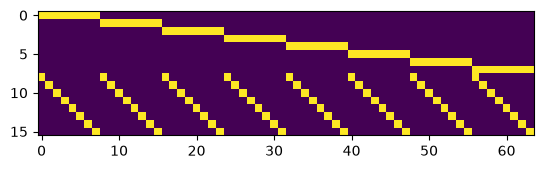

In [4]:
plt.imshow(res[0])

$A$ es una matriz rala (con mucha cantidad de ceros) porque cada fila se trata de una máscara binaria correspondiente a cada rayo. De esta manera, como el rayo atraviesa muy pocos píxeles, la proporción de ceros va a ser mayor a la proporción de unos.

e) Calcular las mediciones $b = Ax_{fantoma}$. Verificar que sus primeras ocho componentes coinciden con `X_fantoma.sum(axis=1)` y las ocho restantes con `X_fantoma.sum(axis=0)`. Graficar ambos bloques como señales unidimensionales.

In [ ]:
X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

b = np.array(res[0]) @ x_fantoma
print(b)

# Calculo las sumas para ver que, efectivamente, dan lo mismo
v1 = X_fantoma.sum(axis=1)
v2 = X_fantoma.sum(axis=0)
print(v1,v2)

[0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
[0.  1.7 3.3 2.3 2.  2.4 1.4 0. ] [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]


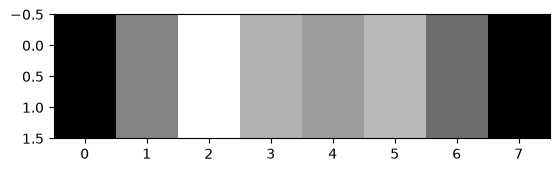

In [20]:
plt.imshow([b[:8],v1], cmap='gray')

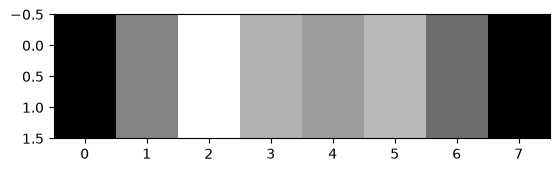

In [21]:
plt.imshow([b[8:],v2], cmap='gray')